In [1]:
%pip install scikit-posthocs seaborn openpyxl

Note: you may need to restart the kernel to use updated packages.


# Avaliação de Equivalência dos Rankings

Lê todos os `Ranking_*.xlsx` da pasta (formato padrão: `Feature`, `Score`, `Ranking`) e faz três coisas:

1. **Friedman + Nemenyi**: mostra quais rankings são estatisticamente equivalentes entre si (p > 0,05) e quais diferem.
2. **Ranking médio das variáveis**: gera um Excel de 3 colunas (colocação, variável, média das posições em todos os rankings). Quanto menor a média, melhor colocada a variável.
3. **Mapa de calor final**: mostra por cores o quanto cada par de rankings é equivalente (diferentes, pouco, moderadamente ou muito equivalentes).

Os métodos são classificados em três grupos: **CEQ** (Cp, Cpk, Pp, Ppk, p, np, c, u), **Descritiva** (AmplitudeSigma, IQRSigma, Assimetria, Curtose) e **Literatura** (os demais).

*Leitura correta do resultado: p > 0,05 significa que o teste **não encontrou diferença** entre os dois rankings; não prova que eles sejam idênticos. Com poucos atributos o teste tem pouco poder e tende a achar equivalência demais.*

*Aviso metodológico: como cada ranking é uma permutação de 1..N das mesmas variáveis, o Friedman/Nemenyi sobre posições pode dar p alto ("equivalentes") mesmo para rankings sem relação alguma. Por isso a tabela de pares traz também o **ρ de Spearman** entre os rankings, e o notebook avisa quando p-valor e ρ discordam.*

### 1. Configurações e pastas

In [2]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scikit_posthocs as sp
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from scipy.stats import friedmanchisquare
import warnings

warnings.simplefilter(action="ignore", category=FutureWarning)

# Mesma pasta onde estão os "Ranking_*.xlsx" gerados nas etapas anteriores
FOLDER = os.getcwd()
OUT_DIR = os.path.join(FOLDER, "Resultados_Completos_Rankings")
os.makedirs(OUT_DIR, exist_ok=True)

print(f"Diretório base: {FOLDER}")
print(f"Salvando resultados em: {OUT_DIR}")

ALPHA = 0.05  # nível de significância usado em todo o notebook

# As versões "_BaseCompleta" das descritivas usam a base inteira (todas as classes),
# então NÃO são pareadas com o CEQ. Por padrão ficam de fora de tudo (Friedman,
# Nemenyi, Excel de médias e mapa de calor). Mude para True para incluí-las.
INCLUIR_BASE_COMPLETA = False

# Faixas do mapa de calor (p-valor do Nemenyi)
FAIXAS = [0.0, 0.05, 0.25, 0.50, 1.0001]
ROTULOS_FAIXAS = [
    "Diferentes (p ≤ 0,05)",
    "Pouco equivalentes (0,05 < p ≤ 0,25)",
    "Moderadamente equivalentes (0,25 < p ≤ 0,50)",
    "Muito equivalentes (p > 0,50)",
]
CORES_FAIXAS = ["#d73027", "#fdae61", "#a6d96a", "#1a9850"]

REGEX_CEQ = re.compile(r"^(Cp|Cpk|Pp|Ppk|p|np|c|u)_(Original|Normalizado)$")
PREFIXOS_DESCRITIVAS = ("AmplitudeSigma", "IQRSigma", "Assimetria", "Curtose")


def grupo_metodo(nome):
    """Classifica o método: 'CEQ', 'Descritiva' ou 'Literatura'."""
    if REGEX_CEQ.match(nome):
        return "CEQ"
    if nome.startswith(PREFIXOS_DESCRITIVAS):
        return "Descritiva"
    return "Literatura"


def is_alvo(nome):
    """Métricas-alvo = CEQ (correspondência exata do nome, sem depender de substring)."""
    return grupo_metodo(nome) == "CEQ"


COR_GRUPO = {"CEQ": "#1f77b4", "Descritiva": "#2ca02c", "Literatura": "#333333"}

Diretório base: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo
Salvando resultados em: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Resultados_Completos_Rankings


### 2. Leitura dos rankings e construção das tabelas

In [3]:
arquivos_encontrados = sorted(
    f for f in os.listdir(FOLDER) if f.startswith("Ranking_") and f.endswith(".xlsx")
)

if not INCLUIR_BASE_COMPLETA:
    ignorados = [f for f in arquivos_encontrados if "_BaseCompleta" in f]
    arquivos_encontrados = [f for f in arquivos_encontrados if "_BaseCompleta" not in f]
    if ignorados:
        print(f"{len(ignorados)} arquivo(s) '_BaseCompleta' fora da análise (INCLUIR_BASE_COMPLETA=False).")

if not arquivos_encontrados:
    raise FileNotFoundError("Nenhum arquivo 'Ranking_*.xlsx' encontrado na pasta.")

print(f"Lendo {len(arquivos_encontrados)} arquivo(s) para gerar tabelas e estatísticas...")

dict_para_estatistica = {}   # Para o teste de Friedman (Ranking alinhado por feature)
dict_tabela_rankings = {}    # Para a Tabela 1 (Features ordenadas por método)
dict_tabela_metricas = {}    # Para a Tabela 2 (Scores alinhados por feature)

for arquivo in arquivos_encontrados:
    path_arq = os.path.join(FOLDER, arquivo)
    try:
        raw_df = pd.read_excel(path_arq)
        raw_df.columns = raw_df.columns.astype(str).str.strip()

        if {"Feature", "Score", "Ranking"}.issubset(raw_df.columns):
            df_temp = raw_df[["Feature", "Score", "Ranking"]].copy()
        elif raw_df.shape[1] >= 3:
            df_temp = raw_df.iloc[:, [0, 1, 2]].copy()
            df_temp.columns = ["Feature", "Score", "Ranking"]
        else:
            print(f"'{arquivo}' não tem colunas suficientes. Ignorado.")
            continue

        df_temp["Feature"] = df_temp["Feature"].astype(str).str.strip()
        df_temp["Score"] = pd.to_numeric(df_temp["Score"], errors="coerce")
        df_temp["Ranking"] = pd.to_numeric(df_temp["Ranking"], errors="coerce")
        df_temp = df_temp.dropna(subset=["Feature", "Ranking"])
        df_temp = df_temp.sort_values(by="Ranking")

        nome_limpo = arquivo.replace(".xlsx", "").replace("Ranking_", "")

        dict_tabela_rankings[nome_limpo] = pd.Series(df_temp["Feature"].values)

        df_temp = df_temp.drop_duplicates(subset=["Feature"], keep="first")
        dict_tabela_metricas[nome_limpo] = pd.Series(df_temp["Score"].values, index=df_temp["Feature"].values)
        dict_para_estatistica[nome_limpo] = pd.Series(df_temp["Ranking"].values, index=df_temp["Feature"].values)

    except Exception as e:
        print(f"[ERRO] Falha ao ler {arquivo}: {e}")

print(f"{len(dict_para_estatistica)} ranking(s) processado(s) com sucesso.")

contagem = pd.Series({m: grupo_metodo(m) for m in dict_para_estatistica}).value_counts()
print("Rankings por grupo:", contagem.to_dict())

ℹ️ 4 arquivo(s) '_BaseCompleta' fora da análise (INCLUIR_BASE_COMPLETA=False).
Lendo 39 arquivo(s) para gerar tabelas e estatísticas...
✅ 39 ranking(s) processado(s) com sucesso.
Rankings por grupo: {'Literatura': 19, 'CEQ': 16, 'Descritiva': 4}


### 3. Exportar tabelas para Excel (apêndice)

In [4]:
print("Gerando planilhas Excel consolidadas...")

df_tabela_rankings = pd.DataFrame(dict_tabela_rankings)
df_tabela_rankings.index = range(1, len(df_tabela_rankings) + 1)
df_tabela_rankings.index.name = "Posição (Ranking)"
df_tabela_rankings.to_excel(os.path.join(OUT_DIR, "1_Tabela_Apendice_Rankings_Ordenados.xlsx"))

df_tabela_metricas = pd.DataFrame(dict_tabela_metricas)
df_tabela_metricas.index.name = "Atributo (Feature)"
df_tabela_metricas.to_excel(os.path.join(OUT_DIR, "2_Tabela_Apendice_Metricas_Scores.xlsx"))

print("Tabelas Excel geradas com sucesso na pasta de saída.")

Gerando planilhas Excel consolidadas...
✅ Tabelas Excel geradas com sucesso na pasta de saída.


### 4. Teste de Friedman

Testa se existe alguma diferença estatística entre os rankings (comparando as posições de cada atributo em comum entre todos os métodos). Só entram atributos presentes em **todos** os rankings.

In [5]:
df_matrix_stat = pd.DataFrame(dict_para_estatistica).dropna()

if df_matrix_stat.shape[0] < 3 or df_matrix_stat.shape[1] < 3:
    raise ValueError("ERRO: Dados insuficientes para estatística (menos de 3 atributos em comum ou menos de 3 métodos).")

print(f"Atributos em comum a todos os rankings: {df_matrix_stat.shape[0]}")
print(f"Rankings comparados: {df_matrix_stat.shape[1]}")

stat, p_friedman = friedmanchisquare(*[df_matrix_stat[col] for col in df_matrix_stat.columns])

print(f"\nEstatística de Friedman: {stat:.4f}")
print(f"P-valor: {p_friedman:.4e}")

diferencas_significativas = p_friedman <= ALPHA

if diferencas_significativas:
    print(f"\nCONCLUSÃO: p <= {ALPHA}. Há diferença estatística entre pelo menos um par de rankings.")
    print("O post-hoc de Nemenyi (próxima etapa) mostra QUAIS pares diferem e quais são equivalentes.")
else:
    print(f"\nCONCLUSÃO: p > {ALPHA}. O Friedman não encontrou diferença entre os rankings.")
    print("O Nemenyi ainda será calculado para o mapa de calor, mas leia-o com cautela.")

Atributos em comum a todos os rankings: 590
Rankings comparados: 39

Estatística de Friedman: 28.7291
P-valor: 8.6139e-01

CONCLUSÃO: p > 0.05. O Friedman não encontrou diferença entre os rankings.
O Nemenyi ainda será calculado para o mapa de calor, mas leia-o com cautela.


### 5. Post-hoc de Nemenyi: quais pares são equivalentes

In [6]:
p_valores_nemenyi = sp.posthoc_nemenyi_friedman(df_matrix_stat)

# Ordem: CEQ, depois Descritivas, depois Literatura (dentro de cada grupo, ordem alfabética)
ordem_grupos = {"CEQ": 0, "Descritiva": 1, "Literatura": 2}
modelos_ordenados = sorted(df_matrix_stat.columns, key=lambda m: (ordem_grupos[grupo_metodo(m)], m))
p_valores_nemenyi = p_valores_nemenyi.loc[modelos_ordenados, modelos_ordenados]

alvos = [m for m in modelos_ordenados if is_alvo(m)]

# Concordância direta entre os rankings (ρ de Spearman sobre as posições)
rho_spearman = df_matrix_stat.corr(method="spearman").loc[modelos_ordenados, modelos_ordenados]
print("Matriz de p-valores do Nemenyi calculada.")

# --- Tabela completa de pares: equivalentes (p > ALPHA) e diferentes ---
linhas = []
cols = p_valores_nemenyi.columns.tolist()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        m1, m2 = cols[i], cols[j]
        p_valor = float(p_valores_nemenyi.loc[m1, m2])
        faixa = ROTULOS_FAIXAS[np.digitize(p_valor, FAIXAS[1:-1], right=True)]
        linhas.append({
            "Método A": m1, "Grupo A": grupo_metodo(m1),
            "Método B": m2, "Grupo B": grupo_metodo(m2),
            "p-valor": round(p_valor, 4),
            "Spearman ρ": round(float(rho_spearman.loc[m1, m2]), 3),
            "Equivalentes (p > 0,05)": p_valor > ALPHA,
            "Faixa": faixa,
        })

df_pares = pd.DataFrame(linhas).sort_values("p-valor", ascending=False).reset_index(drop=True)
df_equivalentes = df_pares[df_pares["Equivalentes (p > 0,05)"]].reset_index(drop=True)

df_pares.to_excel(os.path.join(OUT_DIR, "4_Todos_os_Pares_Nemenyi.xlsx"), index=False)
df_equivalentes.to_excel(os.path.join(OUT_DIR, "4_Pares_Estatisticamente_Equivalentes.xlsx"), index=False)

print(f"\n{len(df_equivalentes)} de {len(df_pares)} pares são estatisticamente equivalentes (p > {ALPHA}).")
print("\nPares por faixa:")
print(df_pares["Faixa"].value_counts().reindex(ROTULOS_FAIXAS).fillna(0).astype(int).to_string())
# --- Diagnóstico: o Nemenyi diz "equivalentes" mas os rankings quase não se correlacionam? ---
RHO_MIN = 0.5
suspeitos = df_equivalentes[df_equivalentes["Spearman ρ"] < RHO_MIN]
print(f"\n{len(suspeitos)} de {len(df_equivalentes)} pares \"equivalentes\" têm ρ de Spearman < {RHO_MIN} "
      "(o teste não achou diferença, mas os rankings concordam pouco).")
if len(suspeitos) > 0:
    print("   Para afirmar equivalência, prefira pares com p > 0,05 E ρ alto. Veja a coluna 'Spearman ρ' nos Excels 4_*.")


✅ Matriz de p-valores do Nemenyi calculada.

📊 741 de 741 pares são estatisticamente equivalentes (p > 0.05).

Pares por faixa:
Faixa
Diferentes (p ≤ 0,05)                             0
Pouco equivalentes (0,05 < p ≤ 0,25)              0
Moderadamente equivalentes (0,25 < p ≤ 0,50)      0
Muito equivalentes (p > 0,50)                   741

⚠️ 192 de 741 pares "equivalentes" têm ρ de Spearman < 0.5 (o teste não achou diferença, mas os rankings concordam pouco).
   Para afirmar equivalência, prefira pares com p > 0,05 E ρ alto. Veja a coluna 'Spearman ρ' nos Excels 4_*.


#### Resumo: com quem cada métrica do CEQ é equivalente

Para cada métrica do CEQ, lista os rankings com p > 0,05, separando **Descritivas** (controle) e **Literatura**.

In [7]:
print(f"Rankings equivalentes a cada métrica do CEQ (p > {ALPHA}):\n")
for alvo in alvos:
    desc, lit, ceq = [], [], []
    for outro in modelos_ordenados:
        if outro == alvo:
            continue
        p_valor = float(p_valores_nemenyi.loc[alvo, outro])
        if p_valor > ALPHA:
            item = f"{outro} (p={p_valor:.2f})"
            {"Descritiva": desc, "Literatura": lit, "CEQ": ceq}[grupo_metodo(outro)].append(item)
    print(f"• {alvo}")
    print(f"    CEQ:        {', '.join(ceq) if ceq else '—'}")
    print(f"    Descritiva: {', '.join(desc) if desc else '—'}")
    print(f"    Literatura: {', '.join(lit) if lit else '—'}")

📌 Rankings equivalentes a cada métrica do CEQ (p > 0.05):

• Cp_Normalizado
    CEQ:        Cp_Original (p=1.00), Cpk_Normalizado (p=1.00), Cpk_Original (p=1.00), Pp_Normalizado (p=1.00), Pp_Original (p=1.00), Ppk_Normalizado (p=1.00), Ppk_Original (p=1.00), c_Normalizado (p=1.00), c_Original (p=1.00), np_Normalizado (p=1.00), np_Original (p=1.00), p_Normalizado (p=1.00), p_Original (p=1.00), u_Normalizado (p=1.00), u_Original (p=1.00)
    Descritiva: AmplitudeSigma (p=1.00), Assimetria (p=1.00), Curtose (p=1.00), IQRSigma (p=1.00)
    Literatura: ANOVA (p=1.00), ApproxMIC (p=1.00), Chi2 (p=1.00), FScore_ANOVA (p=1.00), FisherScore (p=1.00), GainRatio (p=1.00), GiniIndex (p=1.00), HellingerDistance (p=1.00), InformationGain (p=1.00), KS (p=1.00), Kendall (p=1.00), LaplacianScore (p=1.00), Pearson (p=1.00), ReliefF (p=0.99), SPEC (p=1.00), SVDEntropy (p=1.00), Spearman (p=1.00), SymmetricalUncertainty (p=1.00), TScore (p=1.00)
• Cp_Original
    CEQ:        Cp_Normalizado (p=1.00), Cpk_N

### 6. Excel com a média das posições de cada variável

Três colunas: **Colocação**, **Variável** e **Média das posições** da variável em todos os rankings analisados. A variável mais bem colocada é a de **menor média**.

In [8]:
media_posicoes = df_matrix_stat.mean(axis=1)

df_ranking_medio = (
    pd.DataFrame({"Variável": media_posicoes.index, "Média das posições": media_posicoes.values})
    .sort_values(["Média das posições", "Variável"], ascending=[True, True])
    .reset_index(drop=True)
)
df_ranking_medio.insert(0, "Colocação", range(1, len(df_ranking_medio) + 1))
df_ranking_medio["Média das posições"] = df_ranking_medio["Média das posições"].round(4)

path_medio = os.path.join(OUT_DIR, "5_Ranking_Medio_Variaveis.xlsx")
df_ranking_medio.to_excel(path_medio, index=False)

print(f"Ranking médio salvo em: {path_medio}")
print(f"   (média sobre {df_matrix_stat.shape[1]} rankings; {df_matrix_stat.shape[0]} variáveis presentes em todos)\n")
print(df_ranking_medio.head(10).to_string(index=False))

✅ Ranking médio salvo em: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Resultados_Completos_Rankings\5_Ranking_Medio_Variaveis.xlsx
   (média sobre 39 rankings; 590 variáveis presentes em todos)

 Colocação Variável  Média das posições
         1      124             76.8718
         2      103             90.9231
         3      121             99.3077
         4      123            103.4615
         5      180            105.4615
         6       14            108.1538
         7       28            112.1538
         8      129            112.7179
         9      405            113.7692
        10      138            114.5385


### 7. Mapa de calor de equivalência (Nemenyi)

Cada célula é o p-valor entre dois rankings. **Verde escuro** = muito equivalentes, **verde claro** = moderadamente, **laranja** = pouco equivalentes, **vermelho** = estatisticamente diferentes. Os nomes dos eixos seguem o grupo: **azul** = CEQ, **verde** = Descritiva, **cinza-escuro** = Literatura. As linhas brancas grossas separam os grupos.

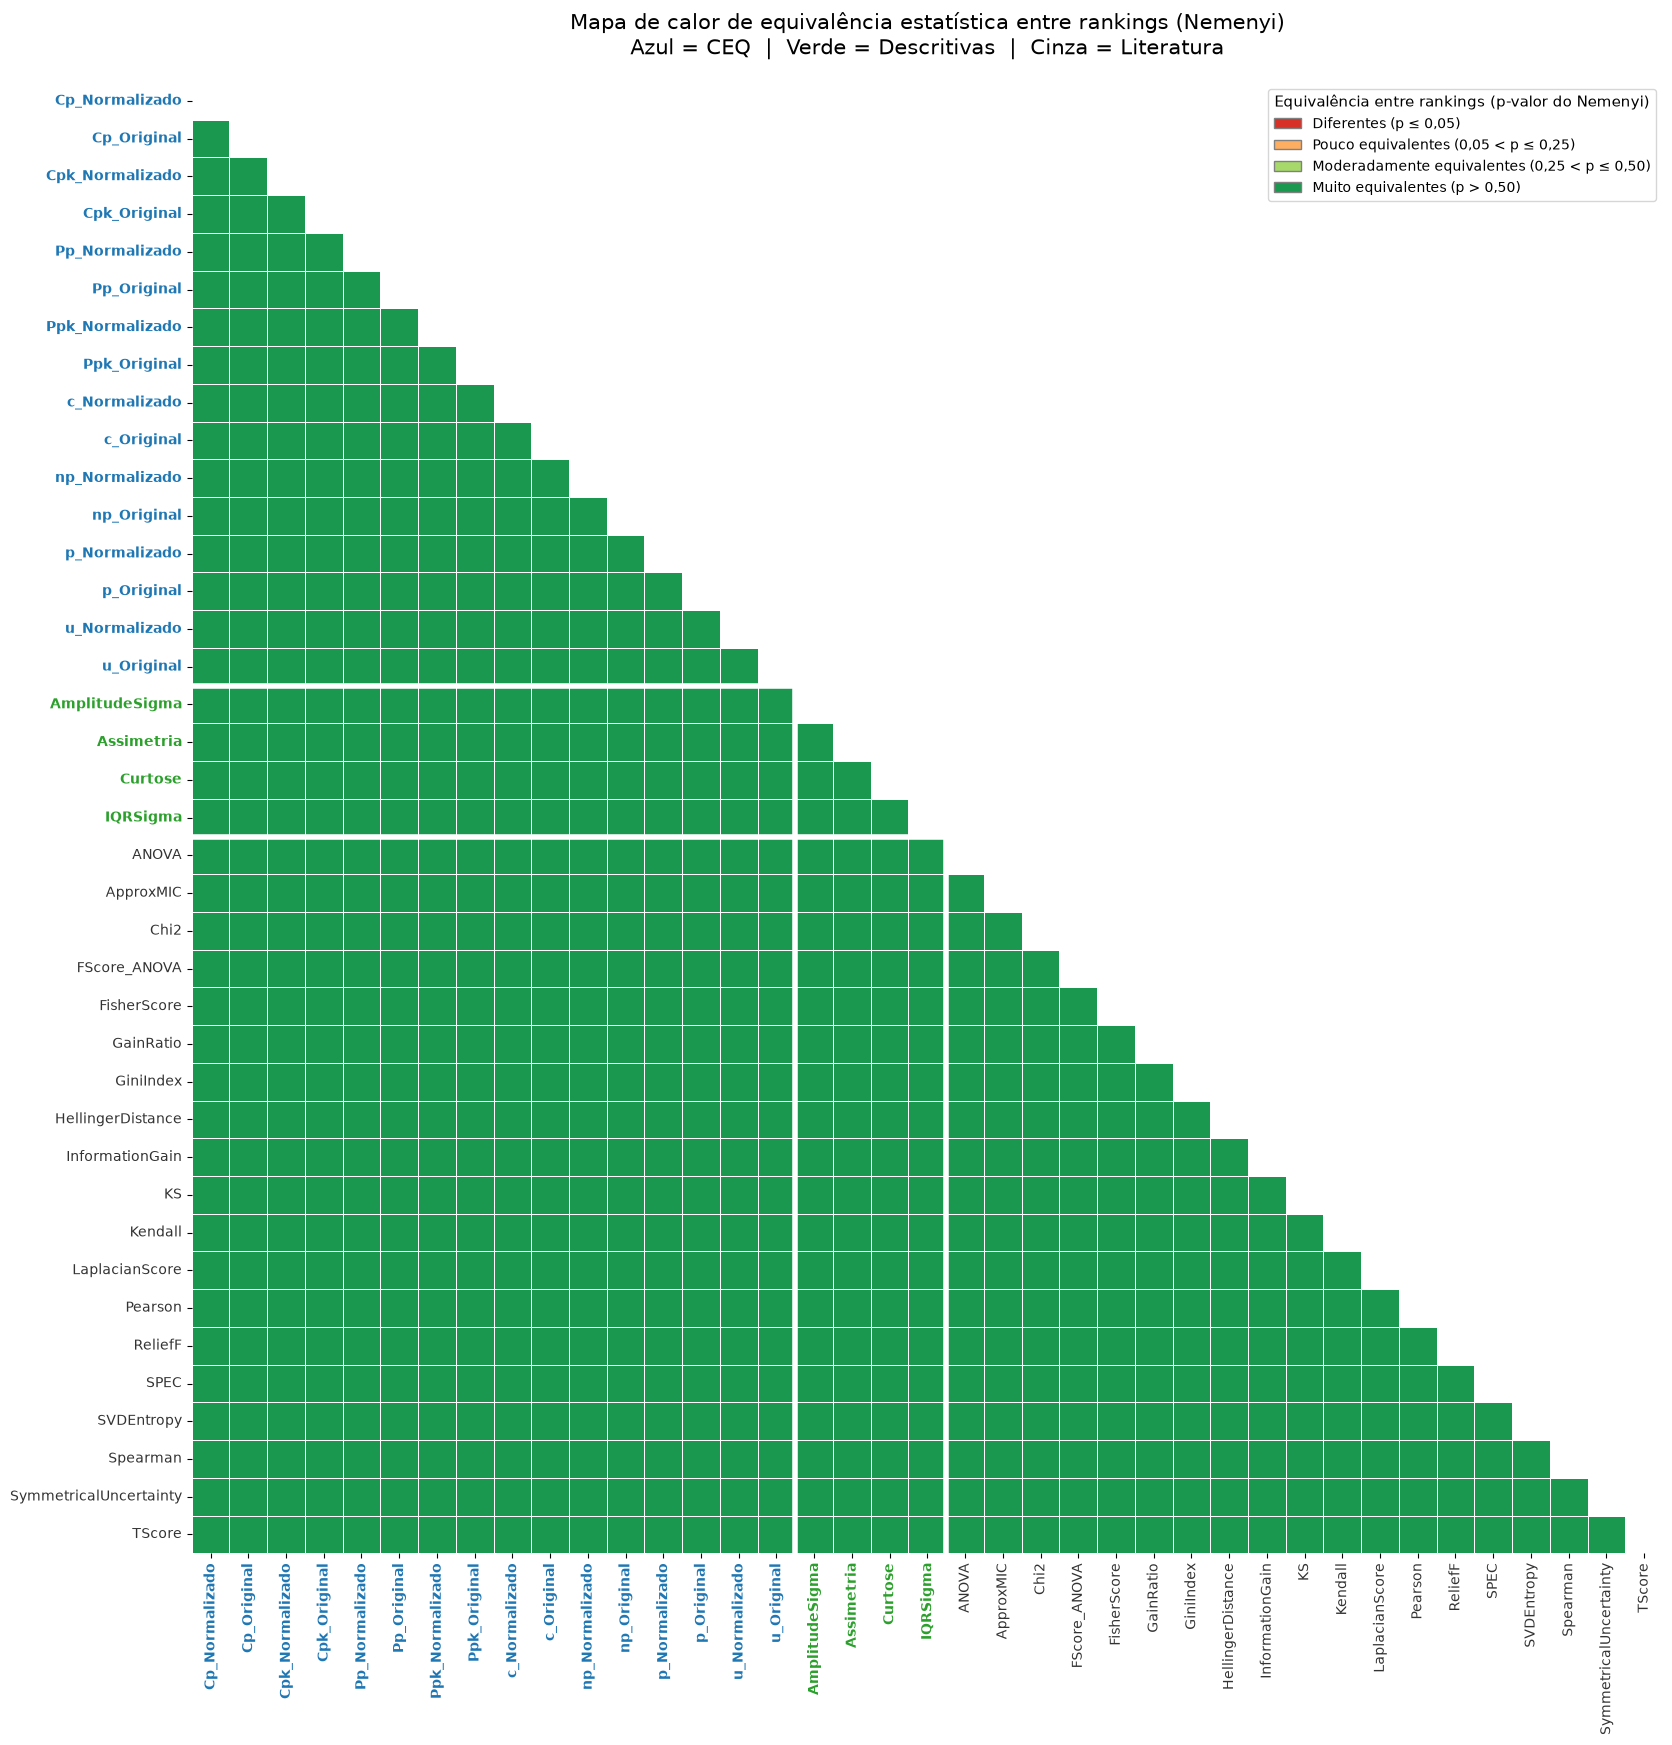

✅ Mapa de calor salvo em: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Resultados_Completos_Rankings\3_Heatmap_Equivalencia_Rankings.png

Processo concluído! Tudo foi gerado em: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Resultados_Completos_Rankings


In [9]:
n = len(modelos_ordenados)
tamanho = max(12, n * 0.45)
fig, ax = plt.subplots(figsize=(tamanho + 3, tamanho))

cmap = ListedColormap(CORES_FAIXAS)
norm = BoundaryNorm(FAIXAS, cmap.N)
mask = np.triu(np.ones_like(p_valores_nemenyi, dtype=bool))  # mostra só o triângulo inferior

sns.heatmap(
    p_valores_nemenyi.astype(float),
    mask=mask, cmap=cmap, norm=norm,
    square=True, linewidths=0.4, linecolor="white",
    annot=(n <= 25), fmt=".2f", annot_kws={"fontsize": 7},
    cbar=False, ax=ax,
)

# Cor dos rótulos por grupo
for lab in list(ax.get_xticklabels()) + list(ax.get_yticklabels()):
    g = grupo_metodo(lab.get_text())
    lab.set_color(COR_GRUPO[g])
    if g != "Literatura":
        lab.set_fontweight("bold")

# Linhas separando os grupos
grupos_seq = [grupo_metodo(m) for m in modelos_ordenados]
for i in range(1, n):
    if grupos_seq[i] != grupos_seq[i - 1]:
        ax.axhline(i, color="white", linewidth=4)
        ax.axvline(i, color="white", linewidth=4)

# Legenda por faixa (no lugar da barra de cores)
patches = [Patch(facecolor=c, edgecolor="gray", label=r) for c, r in zip(CORES_FAIXAS, ROTULOS_FAIXAS)]
ax.legend(handles=patches, title="Equivalência entre rankings (p-valor do Nemenyi)",
          loc="upper right", bbox_to_anchor=(1.0, 1.0), fontsize=10, title_fontsize=11, frameon=True)

ax.set_title("Mapa de calor de equivalência estatística entre rankings (Nemenyi)\n"
             "Azul = CEQ  |  Verde = Descritivas  |  Cinza = Literatura", fontsize=15, pad=20)
plt.xticks(rotation=90)
plt.tight_layout()

file_out_plot = os.path.join(OUT_DIR, "3_Heatmap_Equivalencia_Rankings.png")
plt.savefig(file_out_plot, dpi=300, bbox_inches="tight")
plt.show()

print(f"Mapa de calor salvo em: {file_out_plot}")
print("\nProcesso concluído! Tudo foi gerado em:", OUT_DIR)